<ipython-input-45-d1811d2bf571>:13: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  sns.heatmap(df.corr(), annot= True, cmap="coolwarm")


<Axes: >

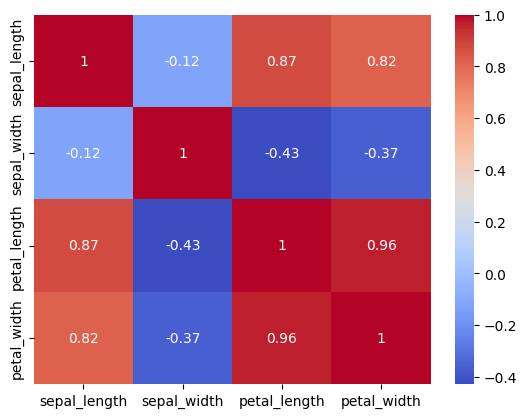

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import sklearn.metrics
import statsmodels.api as sm
import statsmodels.formula.api as smf
import statsmodels.stats as ss

data= sns.load_dataset("iris")
df= data.dropna()

sns.heatmap(df.corr(), annot= True, cmap="coolwarm")

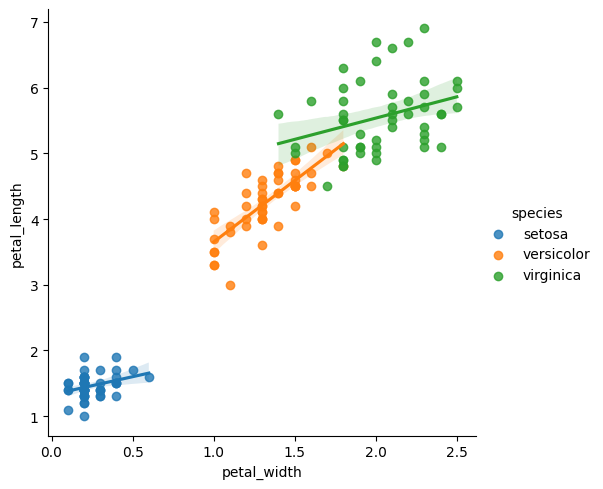

In [ ]:
sns.lmplot(df, x= "petal_width", y= "petal_length", hue= "species")

<Axes: ylabel='Proportion'>

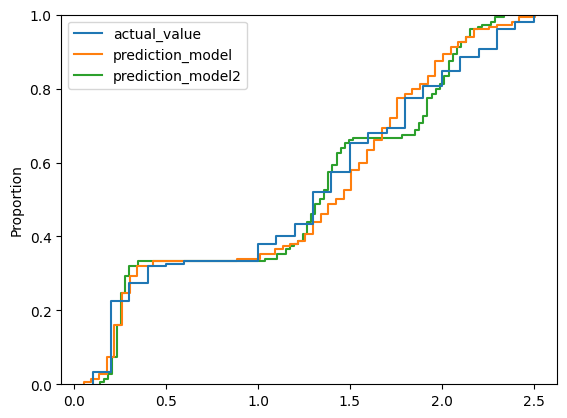

In [ ]:
model= smf.ols( formula= "petal_width ~ petal_length", data= df).fit()
model.summary()

model2= smf.ols( formula= "petal_width ~ petal_length + C(species)", data= df).fit()
model2.summary()

model_results= pd.DataFrame(
    dict(
        actual_value = df.petal_width,
        prediction_model = model.predict(),
        prediction_model2= model2.predict()
    )
)

model_results

sns.ecdfplot(model_results)

In [ ]:
df = df.assign(is_setosa=lambda df: df.species.replace(["setosa", "versicolor", "virginica"], [1, 0, 0]))

model_is_setosa = smf.logit(formula="is_setosa ~ petal_length", data=df).fit()
model_is_setosa.summary()

is_setosa_predictions = pd.DataFrame(
    dict(
        actual_setosa=df.is_setosa,
        predicted_values=model_is_setosa.predict().round()
    )
)

print(is_setosa_predictions.value_counts(["actual_setosa", "predicted_values"]).reset_index(name="count"))

accuracy = sklearn.metrics.accuracy_score(
    is_setosa_predictions.actual_setosa,
    is_setosa_predictions.predicted_values
)

/usr/local/lib/python3.10/dist-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/usr/local/lib/python3.10/dist-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/usr/local/lib/python3.10/dist-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/usr/local/lib/python3.10/dist-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/usr/local/lib/python3.10/dist-packa

         Current function value: 0.000000
         Iterations: 35
   actual_setosa  predicted_values  count
0              0               0.0    100
1              1               1.0     50


In [ ]:
print(accuracy)

1.0
